In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd
from datetime import datetime

In [ ]:
# Step 1: Define the raw data table and column headings for GDP
table_gdp = [
    ['UK', 2678454886796.7],
    ['USA', 1676810000000.0],
    ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8],
    ['South Africa', 366057913367.1]
]
headings_gdp = ['Country', 'GDP (US$)']
gdp = pd.DataFrame(columns=headings_gdp, data=table_gdp)

# Define the raw data table and column headings for life expectancy
table_life = [
    ['China', 75],
    ['Russia', 71],
    ['United States', 79],
    ['India', 66],
    ['United Kingdom', 81]
]
headings_life = ['Country name', 'Life expectancy (years)']
life = pd.DataFrame(columns=headings_life, data=table_life)

In [ ]:
# Step 2: Define a function to scale values down into millions
def roundToMillions(value):
    return round(value / 1000000)

# Define a function to convert US Dollars to British Pounds using the 2013 average exchange rate
def usdToGbp(usd):
    return usd / 1.564768  # average rate during 2013

# Define a function to expand country code abbreviations to their full official names
def expandCountry(name):
    if name == 'UK':
        return 'United Kingdom'
    elif name == 'USA':
        return 'United States'
    else:
        return name

In [ ]:
# Step 3: Apply the expandCountry function to normalize country name representations
gdp['Country name'] = gdp['Country'].apply(expandCountry)

# Convert US Dollar GDP values to British Pounds and round to millions
gdp['GDP (£m)'] = gdp['GDP (US$)'].apply(usdToGbp).apply(roundToMillions)

# Filter and retain only the desired columns ('Country name' and 'GDP (£m)')
headings = ['Country name', 'GDP (£m)']
gdp = gdp[headings]

In [ ]:
# Step 4 (Task): Create the life expectancy dataframe with specified column names
headings_pop = ['Country name', 'Life expectancy (years)']
table_pop = [
    ['China', 75],
    ['Russia', 71],
    ['United States', 79],
    ['India', 66],
    ['United Kingdom', 81]
]
population_df = pd.DataFrame(columns=headings_pop, data=table_pop)

In [ ]:
# Step 5: Perform a Left Join: keeps all rows from left table (gdp) and matches available rows from right
pd.merge(gdp, life, on='Country name', how='left')

#  Perform a Right Join: keeps all rows from right table (life) and matches available rows from left
pd.merge(gdp, life, on='Country name', how='right')

#  Perform an Outer Join: keeps the complete union of all rows from both tables
pd.merge(gdp, life, on='Country name', how='outer')

# Perform an Inner Join: keeps only rows common to both tables (intersection) and stores the result
gdpVsLife = pd.merge(gdp, life, on='Country name', how='inner')

# Display the final inner-joined DataFrame
gdpVsLife

,Country name,GDP (£m),Life expectancy (years)
0,United Kingdom,1711727,81
1,United States,1071603,79
2,China,5905202,75


In [ ]:
# Step 6: Re-initialize the raw gdp dataframe to ensure original columns exist
table_gdp = [
    ['UK', 2678454886796.7],
    ['USA', 1676810000000.0],
    ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8],
    ['South Africa', 366057913367.1]
]
headings_gdp = ['Country', 'GDP (US$)']
gdp = pd.DataFrame(columns=headings_gdp, data=table_gdp)

# Define uppercase constant variables for frequently used column names to prevent typos
GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'
COUNTRY = 'Country name'

# Define helper functions again if needed in this cell
def roundToMillions(value):
    return round(value / 1000000)

def usdToGbp(usd):
    return usd / 1.564768

def expandCountry(name):
    if name == 'UK':
        return 'United Kingdom'
    elif name == 'USA':
        return 'United States'
    else:
        return name

# Apply transformations using the defined constants and functions for consistency
gdp[COUNTRY] = gdp['Country'].apply(expandCountry)
gdp[GDP_GBP] = gdp[GDP_USD].apply(usdToGbp).apply(roundToMillions)
headings = [COUNTRY, GDP_GBP]
gdp = gdp[headings]

# Display the resulting dataframe
gdp

,Country name,GDP (£m)
0,United Kingdom,1711727
1,United States,1071603
2,China,5905202
3,Brazil,1435148
4,South Africa,233937


In [8]:
# Step 7: Import necessary path and database runner modules
import sys
import pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

from db.dataraflow_db import run_query
import pandas as pd

# Step 7: Define indicator constants for World Bank datasets
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
LIFE_INDICATOR = 'SP.DYN.LE00.IN'

#  Query raw data for GDP and Life Expectancy from the week08 schema
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")

# Slice from row 34 onwards to exclude regional aggregates and retain individual countries
gdpCountries = gdpReset[34:]
lifeCountries = lifeReset[34:]

# Drop any rows containing missing data (NaN)
gdpData = gdpCountries.dropna()
lifeData = lifeCountries.dropna()

# Filter columns to keep only country and indicator columns using constants
COUNTRY = 'country'
gdpClean = gdpData[[COUNTRY, GDP_INDICATOR]]
lifeClean = lifeData[[COUNTRY, LIFE_INDICATOR]]

In [9]:
### **Step 8: Merging, Transforming, and Cleaning Combined Data**
# Define transformation functions (if not already defined above)
def roundToMillions(value):
    return round(value / 1000000)

def usdToGbp(usd):
    return usd / 1.564768  # 2013 average exchange rate

# Perform an inner join on the country column to combine GDP and Life Expectancy datasets
gdpVsLifeAll = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')

# Convert GDP from USD to million British Pounds (£m) and round
GDP_COL = 'GDP (£m)'
gdpVsLifeAll[GDP_COL] = gdpVsLifeAll[GDP_INDICATOR].apply(usdToGbp).apply(roundToMillions)

# Round life expectancy values
LIFE_COL = 'Life expectancy (years)'
gdpVsLifeAll[LIFE_COL] = gdpVsLifeAll[LIFE_INDICATOR].apply(round)

# Keep only the final cleaned columns
headings_final = [COUNTRY, GDP_COL, LIFE_COL]
gdpVsLifeClean = gdpVsLifeAll[headings_final]
gdpVsLifeClean.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


The correlation is: 0.5010232389671027
It is statistically significant.


<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

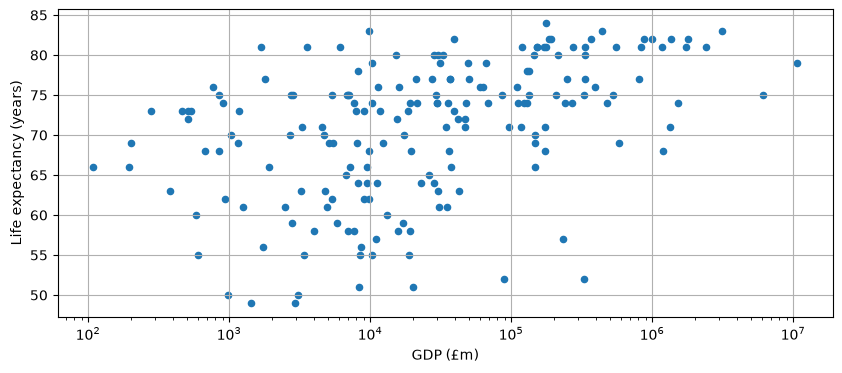

In [10]:
### **Step 9: Correlation and Logarithmic Scatterplot**
# Import Spearman rank correlation from scipy.stats
from scipy.stats import spearmanr

# Calculate Spearman correlation and p-value between GDP and life expectancy
gdpColumn = gdpVsLifeClean[GDP_COL]
lifeColumn = gdpVsLifeClean[LIFE_COL]
correlation, pValue = spearmanr(gdpColumn, lifeColumn)

print('The correlation is:', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

# Enable inline plotting and generate a logarithmic scatterplot
%matplotlib inline
gdpVsLifeClean.plot(x=GDP_COL, y=LIFE_COL, kind='scatter', grid=True, logx=True, figsize=(10, 4))

<Axes: xlabel='Life expectancy (years)', ylabel='GDP (£m)'>

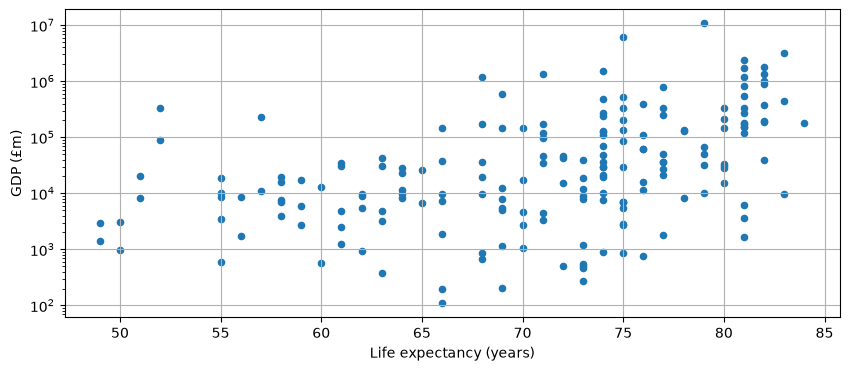

In [11]:
# Task: Swap axes - Life expectancy on x-axis, GDP on y-axis
%matplotlib inline
gdpVsLifeClean.plot(x=LIFE_COL, y=GDP_COL, kind='scatter', grid=True, logy=True, figsize=(10, 4))

<Axes: xlabel='SP.POP.TOTL', ylabel='GDP (£m)'>

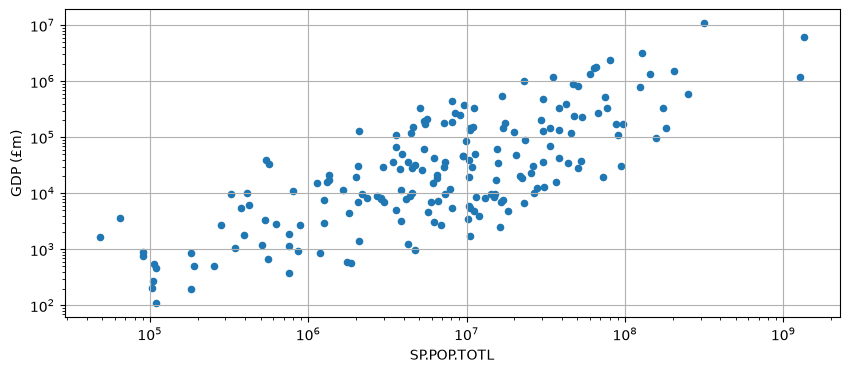

In [13]:
# Task: Display a scatterplot of GDP and Population

# 1. Load and clean the population dataset
popReset = run_query("SELECT * FROM week08.wb_pop_2013")
popCountries = popReset[34:].dropna()
POP_INDICATOR = 'SP.POP.TOTL'
popClean = popCountries[['country', POP_INDICATOR]]

# 2. Merge population data with your main cleaned dataframe 
# (Ensure gdpVsLifeClean is your primary merged dataframe from earlier steps)
gdpLifePop = pd.merge(gdpVsLifeClean, popClean, on='country', how='inner')

# 3. Display the scatterplot for GDP vs. Population
%matplotlib inline
gdpLifePop.plot(x=POP_INDICATOR, y=GDP_COL, kind='scatter', grid=True, logx=True, logy=True, figsize=(10, 4))

In [ ]:
# Assignment Question 1: Compare top 10 countries by GDP vs top 10 by life expectancy
top_gdp_countries = gdpVsLifeClean.sort_values(by=GDP_COL, ascending=False).head(10)
top_life_countries = gdpVsLifeClean.sort_values(by=LIFE_COL, ascending=False).head(10)

# Display results and find the intersection
print("--- Top 10 Countries by GDP ---")
display(top_gdp_countries[[COUNTRY, GDP_COL]])

print("\n--- Top 10 Countries by Life Expectancy ---")
display(top_life_countries[[COUNTRY, LIFE_COL]])

gdp_set = set(top_gdp_countries[COUNTRY])
life_set = set(top_life_countries[COUNTRY])
common_countries = gdp_set.intersection(life_set)

print(f"\nNumber of overlapping countries in both top 10 lists: {len(common_countries)}")
print(f"The matching countries are: {list(common_countries)}")

--- Top 10 Countries by GDP ---


,country,GDP (£m)
177,United States,10715999
35,China,6065182
83,Japan,3143957
62,Germany,2393529
58,France,1795953
176,United Kingdom,1733354
23,Brazil,1528714
81,Italy,1363486
138,Russian Federation,1328647
75,India,1189826



--- Top 10 Countries by Life Expectancy ---


,country,Life expectancy (years)
72,"Hong Kong SAR, China",84
74,Iceland,83
162,Switzerland,83
83,Japan,83
80,Israel,82
81,Italy,82
58,France,82
99,Luxembourg,82
7,Australia,82
161,Sweden,82



Number of overlapping countries in both top 10 lists: 3
The matching countries are: ['Italy', 'France', 'Japan']


In [ ]:
# Assignment Question 2: Identify countries in the right half (higher GDP) with life expectancy below 60 years
median_gdp = gdpVsLifeClean[GDP_COL].median()

outliers = gdpVsLifeClean[
    (gdpVsLifeClean[GDP_COL] > median_gdp) & 
    (gdpVsLifeClean[LIFE_COL] < 60)
].sort_values(by=GDP_COL, ascending=False)

print("--- Countries in the Right Half (Higher GDP) with Life Expectancy < 60 Years ---")
display(outliers[[COUNTRY, GDP_COL, LIFE_COL]])

--- Countries in the Right Half (Higher GDP) with Life Expectancy < 60 Years ---


,country,GDP (£m),Life expectancy (years)
124,Nigeria,329100,52
152,South Africa,234056,57
3,Angola,88420,52


### **3. Explaining Lower Life Expectancy**
*What factors could explain their lower life expectancy compared to countries with similar GDP?*

Despite having a high aggregate GDP (placing them in the right half of the plot), countries like South Africa and Nigeria exhibit lower life expectancy compared to peer economies due to several structural and socio-economic factors:

* **Income Inequality & Wealth Distribution:** High total GDP often driven by natural resource extraction (such as oil or minerals) does not automatically translate to high median household income, widespread public welfare, or reduced poverty levels.
* **Public Health Infrastructure:** Disparities in public healthcare spending per capita lead to uneven access to quality medical care, modern facilities, clean water, and proper sanitation, particularly for rural and lower-income populations.
* **Disease Burden:** A high historical prevalence of communicable diseases and public health epidemics (such as HIV/AIDS and tuberculosis during the evaluation period) disproportionately impacted national mortality and life expectancy rates.

The correlation with GDP per capita is: 0.8503040098920375
It is statistically significant.


<Axes: xlabel='GDP per capita (£)', ylabel='Life expectancy (years)'>

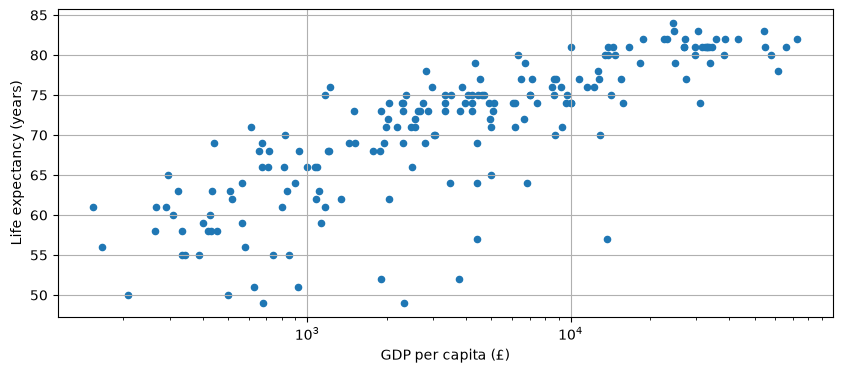

In [ ]:
# Assignment Question 4: Redo analysis using GDP per capita instead of total GDP
popReset = run_query("SELECT * FROM week08.wb_pop_2013")
popCountries = popReset[34:].dropna()
POP_INDICATOR = 'SP.POP.TOTL'
popClean = popCountries[['country', POP_INDICATOR]]

# Merge population data with cleaned GDP and life expectancy DataFrame
gdpLifePop = pd.merge(gdpVsLifeClean, popClean, on='country', how='inner')

# Calculate GDP per capita (converting GDP from millions to absolute value, then dividing by population)
GDP_PER_CAPITA = 'GDP per capita (£)'
gdpLifePop[GDP_PER_CAPITA] = (gdpLifePop[GDP_COL] * 1000000) / gdpLifePop[POP_INDICATOR]

# Recalculate Spearman rank correlation using GDP per capita vs. Life Expectancy
perCapitaColumn = gdpLifePop[GDP_PER_CAPITA]
lifeColumn = gdpLifePop[LIFE_COL]

correlation_pc, pValue_pc = spearmanr(perCapitaColumn, lifeColumn)
print('The correlation with GDP per capita is:', correlation_pc)

if pValue_pc < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

# Generate logarithmic scatterplot for GDP per capita vs. Life Expectancy
%matplotlib inline
gdpLifePop.plot(x=GDP_PER_CAPITA, y=LIFE_COL, kind='scatter', grid=True, logx=True, figsize=(10, 4))

Correlation between GDP and Population: 0.708565007995748
Result is statistically significant.


<Axes: xlabel='SP.POP.TOTL', ylabel='GDP (£m)'>

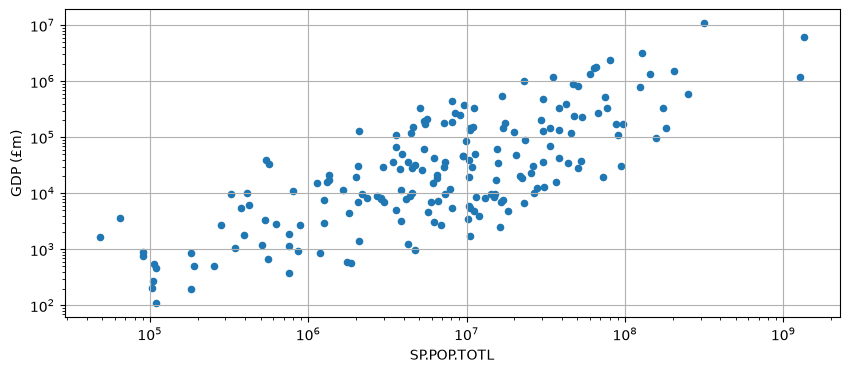

In [ ]:
# Final Task: Scatterplot and correlation analysis of GDP vs. Population
# Using the existing wb_pop_2013 table from the database schema

# Load the population dataset
popReset = run_query("SELECT * FROM week08.wb_pop_2013")

# Clean the dataset by removing regional summary rows and NaNs
popCountries = popReset[34:].dropna()
POP_INDICATOR = 'SP.POP.TOTL'
popClean = popCountries[['country', POP_INDICATOR]]

# Merge population data with our primary cleaned GDP DataFrame
gdpPopPlot = pd.merge(gdpVsLifeClean, popClean, on='country', how='inner')

# Extract columns for correlation testing
gdpCol = gdpPopPlot[GDP_COL]
popCol = gdpPopPlot[POP_INDICATOR]

# Calculate Spearman rank correlation coefficient and test for significance
corr_pop, p_pop = spearmanr(gdpCol, popCol)
print(f'Correlation between GDP and Population: {corr_pop}')
if p_pop < 0.05:
    print('Result is statistically significant.')
else:
    print('Result is not statistically significant.')

# Generate a logarithmic scatterplot to visualize GDP vs. Population
%matplotlib inline
gdpPopPlot.plot(x=POP_INDICATOR, y=GDP_COL, kind='scatter', grid=True, logx=True, logy=True, figsize=(10, 4))